### Fill in group number and member names:

In [1]:
GROUP = "27"
NAME1 = "Gustaf Utterström"
NAME2 = "Philip Rosengren"


# Optimization for learning - FRTN50

## Assignment 1

The goal of this assignment is to become familiar with some of the steps involved in solving an optimization problem. In this assignment, you will form Fenchel dual problems, find gradients and/or proximal operators, and implement the proximal gradient method.

__Problem__ The problem we will solve is the following constrained problem

\begin{align}
	\tag{1}
	\underset{x \in S}{\text{minimize}}\; \tfrac{1}{2}x^T Q x + q^Tx
\end{align}

where $Q\in\mathbb{S}_{++}^{n}$, $q\in\mathbb{R}^{n}$ and $S\subseteq\mathbb{R}^{n}$ is a set defined by the points $a,b\in\mathbb{R}^{n}$, $a\leq b$, such that

\begin{equation*}
	S = \{x \in \mathbb{R}^{n}: a \leq x \leq b \}.
\end{equation*}

I.e., we are going to minimize a quadratic function over an $n$-dimensional box. Recall that, the vector inequality $a\leq b$ means that

\begin{align*}
	a_{i} \leq b_{i}
\end{align*}

for each $i=1,\ldots,n$. Define the function $f:\mathbb{R}^{n}\rightarrow\mathbb{R}$ such that

\begin{align*}
	f(x) = \tfrac{1}{2}x^T Q x + q^Tx
\end{align*}

for each $x\in\mathbb{R}^{n}$ and let $\iota_{S}:\mathbb{R}^{n}\rightarrow\mathbb{R}\cup\{\infty\}$ denote the indicator function of the set $S$, i.e.,

\begin{align*}
	\iota_{S}(x) =
	\begin{cases}
		0 		& \text{if }x\in S, \\
		\infty 	& \text{if }x\in \mathbb{R}^n \setminus S.
	\end{cases}
\end{align*}

Problem $(1)$ can then be written as

\begin{align}
	\tag{2}
	\underset{x \in \mathbb{R}^{n}}{\text{minimize}}\; f(x) + \iota_{S}(x).
\end{align}

__Solution method__ To solve optimization problem $(2)$, we will use the _proximal gradient method_. It solves problems of the form

\begin{align}
	\tag{3}
	\underset{x \in \mathbb{R}^{n}}{\text{minimize}}\; f(x) + g(x)
\end{align}

where $f:\mathbb{R}^{n}\rightarrow\mathbb{R}$ is differentiable and $g:\mathbb{R}^{n}\rightarrow\mathbb{R}\cup\{\infty\}$ is proximable, i.e., $\operatorname{prox}_{\gamma g}$ can be cheaply computed. The proximal gradient method (with constant step-size) is given by:

- Pick some arbitrary initial guess $x^0\in\mathbb{R}^{n}$ and step-size $\gamma>0$.
- For $k=0,1,2\ldots$, let
\begin{align}
\tag{4}
				x^{k+1} = \operatorname{prox}_{\gamma g}\left(x^k - \gamma \nabla f(x^k)\right).
\end{align}
- Stop when $x^k$ is deemed to have converged.

In this assignment, we simply run the proximal gradient method a large fixed number of iterations and plot the norm of the fixed-point residual $| \lvert x^{k+1} - x^k \rvert |_{2}$ (also known as the step-length), of each step to make sure it converges to zero. Since the experiments are run on a computer, zero means smaller than machine precision, which usually is around $10^{-15}$.

The step-size parameter $\gamma$ in the $(4)$ will affect the convergence. It should be tuned to the problem or chosen based on properties of $f$ and $g$. In particular, suppose that $f$ and $g$ are proper, closed and convex.
If $f$ is $\beta$-smooth for some parameter $\beta>0$, the maximal step-size to guarantee convergence is $\gamma < \frac{2}{\beta}$.

Below are the tasks that you need to solve. Keep this in mind:
- The suggested exercises in the exercise compendium found on the Canvas course page, up until and including the chapter "Proximal gradient method - basics", is relevant for this assignment.
- Carefully motivate every step in your calculations.
- Use __figures__ and __tables__ to motivate your answers.
- Figures must have appropriately labeled axes and must be referenced in the main text.
- Your code should be written in a quite general manner, i.e., if a question is slightly modified, it should only require slight modifications in your code as well.
- Comment your code well.
- Make sure you plot in such a way that small quantities (e.g., $|\lvert x^{k+1} - x^k \lvert|_2$) are visible. In particular, use log-linear plots, where the quantity that should go to $0$ is on the $y$-axis using logarithmic scale, and the iteration number $k$ on the $x$-axis using linear scale.
- What you need to submit to Canvas:
    - This jupyter notebook containing your solutions.
    - An exported pdf version of the jupyter notebook. (One way to do this is to print the notebook in your web browser, and then save as pdf.)

This table shows which lectures are needed in order to solve task 1-7:
    
| Task | Lectures |
| ---- | -------- |
| 1    | 2, 3     |
| 2    | 4        |
| 3    | 3, 4     |
| 4    | 2, 4     |
| 5    | 3, 4     |
| 6    | 5        |
| 7    | 4        |

Task 8-10 can be solved after you have solved task 1-7.


---
### Task 1:

Show that $f$ and $\iota_{S}$ in $(2)$ are convex and show that constraint qualification (CQ) holds. You are allowed to assume that $\operatorname{relint} S \neq \emptyset$. Note that $f$ and $\iota_{S}$ also are closed, but you do not need to prove this.

__Solution:__



One can show that $f$ is convex by calculating the Hessian of $f$:
\begin{aligned}
    &\nabla f(x) = \frac{1}{2}(Q+Q^T)x + q = Qx +q \rightarrow \\
    &\nabla^2 f(x) = Q
\end{aligned}
This holds since $Q\in S^n_{++}$ and hence symetric and positive definite. Therefore, $ \nabla^2 f(x) \succ 0$ and hence $f$ is convex.
To show that $\iota_s$ is convex one can use the definition of convexity. Firstly, I want to show that the set $S$ is convex by showing that $\lambda x +(1-\lambda)y \in S$ for $x,y \in S \text{ and } \lambda \in [0,1]$. One then get (by multiplying and adding with $\lambda \text{ and } 1-\lambda$ ):
\begin{aligned}
    &a\leq x \leq b \\
    &a\leq y \leq b\\
    &a = \lambda a +(1-\lambda)a \leq \lambda x + (1-\lambda)y \leq \lambda b + (1-\lambda)b =b
\end{aligned}
From this, one can conclude that $\lambda x + (1-\lambda)y \in S$ and hence $S$ is convex. Now, we can take $x,y \in S$. Since $S$ is convex we now that $0=\iota (\lambda x + (1-\lambda)y) \leq \lambda \iota (x) + (1-\lambda)(y)=0$. If $x,y$ is not in $S$ then $ \lambda \iota (x) + (1-\lambda)(y) = \infty $. Therefore, $ \iota (\lambda x + (1-\lambda)y) \leq \infty$. This holds trivially even at the end-cases for $\lambda =0, \lambda =1$. Hence, $\iota$ is convex.

To show that the CQ-holds one can first conclude that since $f$ is finite for every $x\in R^n$, $dom f = R^n$ must hold. Therefore, relint(dom $f$) = $R^n$. For the indicator function dom $\iota_S$=S. This yields, relint (dom $\iota_S$ )=relint S. This gives: relint(dom $f$)$\cap$  relint (dom $\iota_S$ ) = $R^n$ $\cap$ relint S = relint S $\neq \emptyset$  






---
### Task 2:

Compute the conjugate functions $f^\ast$ and $\iota_{S}^\ast$. The final expressions are not allowed to be given implicitly via optimization problems. E.g., projection formulas must be solved explicitly.

__Solution:__

Since $f(x)$ is differentiable and convex (from task 1) one can write the subdifferential as $\partial f(x) = \{Qx+q\}$, this follows from the expression of the gradient in task 1. By using Fermat's rule, we can set the subdiferential equal to zero and solve for $x$. For $s\in \partial f(x)$:
\begin{aligned}
    & s=Qx+q \rightarrow x= Q^{-1}(s-q)
\end{aligned}
This holds since Q is invertible by definition. Fenchel-Young's equality then gives:
\begin{aligned}
    &f^{*}(s)=s^T(Q^{-1}(s-q))-f(Q^{-1}(s-q))= s^T (Q^{-1}(s-q)) - \frac{1}{2}(s-q)^T Q^{-1}QQ^{-1}(s-q) - q^T Q^{-1}(s-q)\\
    &= \frac{1}{2}(s-q)^TQ^{-1}(s-q)
\end{aligned}
Since $S$ is a box, it is separable across coordinates so we can compute $\iota_S^*(s)$ coordinate-by-coordinate and sum the results. We therefore consider $x_i, s_i \in R$. For a single coordinate, $\iota_{[a_i,b_i]}(x_i)$ has subdifferential (has been shown in exercises):

$$
\partial \iota_{[a_i,b_i]}(x_i) =
\begin{cases}
(-\infty,0] & \text{if } x_i = a_i,\\
\{0\} & \text{if } x_i \in (a_i,b_i),\\
[0,\infty) & \text{if } x_i = b_i,\\
\emptyset & \text{otherwise}.
\end{cases}
$$

We have three cases for $s_i$ (here f($\cdot)$ = $\iota_{[a_i,b_i]}(\cdot))$.

- if $s_i \in (-\infty,0)$. Then $s_i \in \partial\iota_{[a_i,b_i]}(x_i)$ implies $x_i = a_i$. Fenchel–Young's equality gives
$$
f^*(s_i) = s_i \cdot a_i - f(a_i) = a_is_i - 0 = a_is_i.
$$
- if $s_i = 0$. Then $s_i \in \partial\iota_{[a_i,b_i]}(x_i)$ implies $x_i \in [a_i,b_i]$. Fenchel–Young's equality gives
$$
f^*(0) = 0 \cdot x_i - f(x_i) = 0 - 0 = 0.
$$
- if $s_i \in (0,\infty)$. Then $s_i \in \partial\iota_{[a_i,b_i]}(x_i)$ implies $x_i = b_i$. Fenchel–Young's equality gives

$$
f^*(s_i) = s_i \cdot b_i - f(b_i) = b_is_i - 0 = b_is_i.
$$

This covers all cases for $s_i$,:
$$
f^*(s_i) =
\begin{cases}
a_is_i & s_i < 0,\\
0 & s_i = 0,\\
b_is_i & s_i > 0
\end{cases}
\;=\; b_i\max(s_i,0) + a_i\min(s_i,0).
$$

We can now take the sum over all coordinates:

$$
\iota_S^*(s) = \sum_{i=1}^n \iota_{[a_i,b_i]}^*(s_i) = \sum_{i=1}^n\Big(b_i\max(s_i,0) + a_i\min(s_i,0)\Big) =\iota_S^*(s) = b^T\max(0,s) + a^T\min(0,s)
$$
With $max(0,s),min(0,s)$ is the element wise max/min of the vector $s$.


---
### Task 3:

Write down a Fenchel dual problem to $(2)$. Show that constraint qualification for the dual problem (CQ-D) holds.

_Attention/hint:_ Keep track of your minus signs.

__Solution:__


Fermat's rule gives that $x\in R^n$ is an optimal solution to the primal in (2) problem if:

$$
 0 \in \partial (f+g)(x)
$$

Since $f$ and $g$ is proper and convex we can use the subdifferential sum rule:

$$
 0 \in \partial f(x) + \partial g(x)
$$
This means that it exist a point $\mu \in R^n$ such that:
$$
\begin{cases}
\mu \in \partial f(x)\\
-\mu \in \partial g(x)
\end{cases}
$$
Since $f$ and $g$ are proper closed and convex we can use the partial-inverse-conjugate rule which gives:
$$
\begin{cases}
x \in \partial f^*(\mu)\\
x \in \partial g^*(-\mu)
\end{cases}
$$

This is equivalent to that:
$$
 0 \in \partial f^*(\mu) -\partial g^*(-\mu)
$$

By fermats rule, this gives:
$$
 minimize_{\mu \in R^n} f^*(\mu) + g^*(-\mu)
$$
Which is the fenchel dual problem to (2). We can now use the conjugate functions from task 2: $f^*(\mu) = \frac{1}{2}(\mu-q)^TQ^{-1}(\mu-q)$, $g(-\mu)= b^T\max(0,-\mu) + a^T\min(0,-\mu)$. This gives:

$$
minimize_{\mu \in R^n}  \frac{1}{2}(\mu-q)^TQ^{-1}(\mu-q) + b^T\max(0,-\mu) + a^T\min(0,-\mu)
$$
This can also be written as:
$$
minimize_{\mu \in R^n}
\frac{1}{2}(\mu-q)^T Q^{-1}(\mu-q)
+
\sum_{i=1}^{n}
\begin{cases}
-a_i\mu_i, & \mu_i \geq 0,\\
-b_i\mu_i, & \mu_i < 0.
\end{cases}
$$

For the CQ-D the follwing must hold:

$$
\operatorname{relint}(\operatorname{dom} f^*) \cap \operatorname{relint}(\operatorname{dom}\iota_S^*) \neq \emptyset.
$$

Since $Q > 0$, $Q^{-1}$ exists and is finite. $q \in R^n$ is a finite vector. This means that $f^*(s)$ is finite for every $s\in R^n$, giving $\operatorname{dom}f^* = R^n$.  Since $\iota_S^*(s) = b^T\max(0,s) + a^T\min(0,s)$ and $a,b\in R^n$ are fixed finite vectors, this expression is finite for every $s\in R^n$, so $\operatorname{dom}\iota_S^*=\R^n$.

Hence

$$
\operatorname{relint}(\operatorname{dom}f^*)\cap\operatorname{relint}(\operatorname{dom}\iota_S^*) = \mathbb{R}^n \cap \mathbb{R}^n = \mathbb{R}^n \neq \emptyset,
$$

so CQ-D holds


---
### Task 4:

Show that $f$ and $f^*$ are $\beta$-, and $\beta^*$-smooth, respectively. Find expressions for the smallest such parameters $\beta$ and $\beta^*$. For instance, show that for any $\beta' < \beta$ we have that $f$ is not $\beta'$-smooth.

_Hint:_ Later when calculating the smoothness parameters in Pyhton, make sure to read the documentation carefully so that you use the correct function.

__Solution:__

#### Smoothness of $f$

 Let $\lambda_i, i\in\mathbb{1\dots n} $ be the eigenvalues of $Q$. They are real and positive since $Q\in\mathbb{S}^n_{++}$.

Since $Q$ is symmetric, $f(x)=\tfrac12 x^TQx + q^Tx$ is twice differentiable:
$$\nabla f(x) = Qx + q, \qquad \nabla^2 f(x) = Q$$

Second-order condition for smoothness: $f$ is $\beta$-smooth $\iff-\beta I \preceq Q \preceq \beta I$.

- $Q \preceq \beta I \iff \beta I - Q \succeq 0 \iff \beta - \lambda_i \geq 0$ $ \forall i$, since $\beta I - Q$ has eigenvalues $\beta-\lambda_i(Q)$. This holds if adn only if $\beta\geq\lambda_{\max}$.
- $-\beta I \preceq Q$ holds automatically for every $\beta\geq 0$, since $Q\succ 0$.

$f$ is $\beta$-smooth $\iff$ $\beta\geq\lambda_{\max}$, with smallest beta:$${\beta_{min} = \lambda_{\max}(Q)}.$$

*$f$ is not $\beta'$-smooth for any $\beta'<\beta$.* This holds automatically from the if and only if above.

#### Smoothness of $f^*$

From task 2:
$$f^*(s) = \tfrac12 (s-q)^TQ^{-1}(s-q).$$

$Q^{-1}$ exists and is symmetric since $Q\in\mathbb{S}^n_{++}$, so $f^*$ is twice differentiable:
$$\nabla f^*(s) = Q^{-1}(s-q), \qquad \nabla^2 f^*(s) = Q^{-1}$$

The eigenvalues of $Q^{-1}$ are $1/\lambda_i$, which are real and positive so $Q^{-1}\in\mathbb{S}^n_{++}$. The largest eigenvalue of $Q^{-1}$ is $1/\lambda_{\min}$.

Second-order condition for smoothness: $f^*$ is $\beta^*$-smooth $\iff$ $-\beta^* I \preceq Q^{-1} \preceq \beta^* I$.

- $Q^{-1} \preceq \beta^* I \iff \beta^* I - Q^{-1} \succeq 0 \iff \beta^* - 1/\lambda_i \geq 0$ $\forall i$, since $\beta^* I - Q^{-1}$ has eigenvalues $\beta^* - 1/\lambda_i$. This holds if and only if $\beta^*\geq 1/\lambda_{\min}$
- $-\beta^* I \preceq Q^{-1}$ holds automatically for every $\beta^*\geq 0$, since $Q^{-1}\succ 0$

$f^*$ is $\beta^*$-smooth $\iff$ $\beta^*\geq 1/\lambda_{\min}$, with smallest $\beta^*$: $${\beta^*_{min}  = \frac{1}{\lambda_{\min}(Q)}}.$$

*$f^*$ is not $\beta'$-smooth for any $\beta'<\beta^*_{min}$.* This holds automatically from the if and only if above.


---
### Task 5:

Compute $\nabla f$, $\nabla f^\ast$, $\operatorname{prox}_{\gamma\iota_{S}}$ and $\operatorname{prox}_{\gamma\iota_{S}^\ast}$. The final expressions are not allowed to be given implicitly via optimization problems. E.g., projection formulas must be solved explicitly.


__Solution:__

#### Gradients

$f(x) = \tfrac12 x^TQx + q^Tx$, a quadratic and $Q$ symmetric:
$$\nabla f(x) = Qx + q$$

$f^*(s) = \tfrac12 (s-q)^TQ^{-1}(s-q)$, a quadratic and $Q^{-1}$ symmetric:
$$\nabla f^*(s) = Q^{-1}(s-q)$$

#### $\operatorname{prox}_{\gamma\iota_S}$

Since $\gamma\cdot 0 = 0$ and $\gamma\cdot\infty = \infty$ for $\gamma>0$, we have $\gamma\iota_S = \iota_S$, so
$$\operatorname{prox}_{\gamma\iota_S}(z) = \operatorname{prox}_{\iota_S}(z)$$

$\iota_S$ is separable, $\iota_S(x) = \sum_{i=1}^n \iota_{[a_i,b_i]}(x_i)$, so the prox decomposes into:
$$\left(\operatorname{prox}_{\gamma\iota_S}(z)\right)_i = \operatorname{argmin}_{a_i\leq x_i\leq b_i} \tfrac12 (x_i - z_i)^2.$$

$(x_i - z_i)^2$ is minimized at $x_i = z_i$ if $z_i\in[a_i,b_i]$. Otherwise it is minimized at the endpoint closest to $z_i$:
$$\left(\operatorname{prox}_{\gamma\iota_S}(z)\right)_i =
\begin{cases}
a_i & \text{if } z_i < a_i \\
z_i & \text{if } a_i\leq z_i\leq b_i \\
b_i & \text{if } z_i > b_i
\end{cases}$$

#### $\operatorname{prox}_{\gamma\iota_S^*}$

$$\iota_S^*(s) = \sup_{x\in\mathbb{R}^n}\left(s^Tx - \iota_S(x)\right) = \sup_{x\in S} s^Tx,$$
since $s^Tx - \iota_S(x) = -\infty$ for $x\notin S$ and $s^Tx - \iota_S(x) = s^Tx$ for $x\in S$.

$S$ is a box, so $s^Tx = \sum_{i=1}^n s_ix_i$ and each $x_i$ $\in$ $[a_i,b_i]$. The sup separates into:
$$\iota_S^*(s) = \sup_{x\in S}\sum_{i=1}^n s_ix_i = \sum_{i=1}^n h_i(s_i), \qquad h_i(s_i) = \sup_{a_i\leq x_i\leq b_i} s_ix_i.$$

$s_ix_i$ is linear in $x_i$, so it is maximized at an endpoint: at $x_i = b_i$ if $s_i\geq 0$ and at $x_i = a_i$ if $s_i<0$. So
$$h_i(s_i) = \begin{cases} a_is_i & \text{if } s_i<0 \\ b_is_i & \text{if } s_i\geq 0\end{cases} $$

Since $\iota_S^*$ is separable, the prox can be separated:
$$\left(\operatorname{prox}_{\gamma\iota_S^*}(z)\right)_i = \operatorname{prox}_{\gamma h_i}(z_i).$$

Subdifferential of $h_i$ (using $a_i\leq b_i$): $h_i$ is differentiable for $s_i\neq 0$, and at $s_i = 0$ the gradients from each side are $a_i$ and $b_i$:
$$\partial h_i(s_i) =
\begin{cases}
\{a_i\} & \text{if } s_i < 0 \\
[a_i, b_i] & \text{if } s_i = 0 \\
\{b_i\} & \text{if } s_i > 0
\end{cases}$$

Fermat's rule: $s_i = \operatorname{prox}_{\gamma h_i}(z_i)$: $0\in\partial h_i(s_i) + \gamma^{-1}(s_i - z_i)$.

- $s_i < 0$: $0 = a_i + \gamma^{-1}(s_i - z_i) \iff s_i = z_i - \gamma a_i$, valid if $z_i < \gamma a_i$.
- $s_i = 0$: $0 \in [a_i,b_i] - \gamma^{-1}z_i \iff z_i\in[\gamma a_i, \gamma b_i]$.
- $s_i > 0$: $0 = b_i + \gamma^{-1}(s_i - z_i) \iff s_i = z_i - \gamma b_i$, valid if $z_i > \gamma b_i$.

$$\left(\operatorname{prox}_{\gamma\iota_S^*}(z)\right)_i =
\begin{cases}
z_i - \gamma a_i & \text{if } z_i < \gamma a_i \\
0 & \text{if } \gamma a_i\leq z_i\leq \gamma b_i \\
z_i - \gamma b_i & \text{if } z_i > \gamma b_i
\end{cases}$$

---

### Task 6:

Based on your results above, write explicitly out the proximal gradient update rule $(4)$ for both the primal and the dual problem. Use $x$ as the primal variable and $\mu$ as the dual variable.

_Attention/hint:_ Keep track of your minus signs.

__Solution:__

The proximal gradient method solves $\text{minimize}\; f(x) + g(x)$, where $f$ is $\beta$-smooth (and convex) and $g$ is proper closed and convex, via
$$x^{k+1} = \operatorname{prox}_{\gamma g}\left(x^k - \gamma\nabla f(x^k)\right).$$

#### Primal update

Gradient step on $f$, using $\nabla f(x) = Qx + q$ from Task 5:
$$z^k = x^k - \gamma(Qx^k + q)$$

Prox step on $\iota_S$, using $\operatorname{prox}_{\gamma\iota_S}$ from Task 5:
$$x_i^{k+1} =
\begin{cases}
a_i & \text{if } z_i^k < a_i \\
z_i^k & \text{if } a_i\leq z_i^k\leq b_i \\
b_i & \text{if } z_i^k > b_i
\end{cases}$$

#### Dual update

The dual of $\text{minimize}_x\; f(Lx) + g(x)$ is $\text{minimize}_{\mu}\; f^*(\mu) + g^*(-L^T\mu)$. With $L = I$ and $g = \iota_S$:
$$\text{minimize}_\mu\; f^*(\mu) + \iota_S^*(-\mu),$$
with smooth part $f^*$ and nonsmooth part $\tilde g(\mu) := \iota_S^*(-\mu)$.

By the prox definition,
$$\operatorname{prox}_{\gamma\tilde g}(z) = \operatorname{argmin}_{\mu}\left(\iota_S^*(-\mu) + \tfrac{1}{2\gamma}\|\mu - z\|_2^2\right).$$
Substitute $y = -\mu$, so that $\|\mu - z\|_2 = \|y - (-z)\|_2$:
$$y^\star = \operatorname{argmin}_{y}\left(\iota_S^*(y) + \tfrac{1}{2\gamma}\|y - (-z)\|_2^2\right) = \operatorname{prox}_{\gamma\iota_S^*}(-z),$$
and $\mu^\star = -y^\star$, so $\operatorname{prox}_{\gamma\tilde g}(z) = -\operatorname{prox}_{\gamma\iota_S^*}(-z)$.

Inserting $-z_i$ into $\operatorname{prox}_{\gamma\iota_S^*}$ from Task 5 and negating:

- $-z_i < \gamma a_i \iff z_i > -\gamma a_i$: $\;-(-z_i - \gamma a_i) = z_i + \gamma a_i$.
- $\gamma a_i \leq -z_i \leq \gamma b_i \iff -\gamma b_i \leq z_i \leq -\gamma a_i$: $\;-0 = 0$.
- $-z_i > \gamma b_i \iff z_i < -\gamma b_i$: $\;-(-z_i - \gamma b_i) = z_i + \gamma b_i$.

Gradient step on $f^*$, using $\nabla f^*(\mu) = Q^{-1}(\mu - q)$ from Task 5:
$$v^k = \mu^k - \gamma\nabla f^*(\mu^k) = \mu^k - \gamma Q^{-1}(\mu^k - q)$$

Prox step on $\tilde g$, using $\operatorname{prox}_{\gamma\tilde g}$ derived above:
$$\mu^{k+1} = \operatorname{prox}_{\gamma\tilde g}(v^k),$$
which componentwise gives
$$\mu_i^{k+1} =
\begin{cases}
v_i^k + \gamma a_i & \text{if } v_i^k > -\gamma a_i \\
0 & \text{if } -\gamma b_i \leq v_i^k \leq -\gamma a_i \\
v_i^k + \gamma b_i & \text{if } v_i^k < -\gamma b_i
\end{cases}$$


---
### Task 7:

Suppose that $\mu^\star\in\mathbb{R}^{n}$ is an optimal solution to the dual problem you found in Task 3. Given $\mu^\star$, and __starting from the optimality condition for the dual problem (given by _Fermat's rule_)__, recover an optimal point $x^{\star}\in\mathbb{R}^{n}$ to the primal problem $(2)$, and show that this $x^{\star}$ is in fact an optimal solution to the primal problem (2). Motivate each step in your argument carefully.

__Solution:__

### Task 7:

__Solution:__

Lecture facts used:
- Fermat's rule: $x$ minimizes $f$ if and only if $0\in\partial f(x)$.
- Subdifferential of sum: If $f_1, f_2$ closed convex and $\operatorname{relint}\operatorname{dom}f_1 \cap \operatorname{relint}\operatorname{dom}f_2 \neq \emptyset$: $\partial(f_1+f_2) = \partial f_1 + \partial f_2$. One direction always holds: if $x\in\operatorname{dom}\partial f_1\cap\operatorname{dom}\partial f_2$: $\partial(f_1+f_2)(x)\supseteq\partial f_1(x)+\partial f_2(x)$.
- Subdifferential of composition: If $f$ closed convex and $\operatorname{range}(L)\cap\operatorname{relint}\operatorname{dom}f\neq\emptyset$: $\partial(f\circ L)(x) = L^T\partial f(Lx)$.
- Relation to gradient: If $f$ differentiable at $x$ and $\partial f(x)\neq\emptyset$ then $\partial f(x) = \{\nabla f(x)\}$.
- Conjugate properties: $f^*$ convex and closed.
- Relation between $\partial f$ and $\partial f^*$: $s\in\partial f(x)$ implies $x\in\partial f^*(s)$.
- Biconjugate: $f^{**} = f$ if and only if $f$ (closed and) convex.

#### Dual optimality condition

The dual problem is
$$\text{minimize}_\mu\; f^*(\mu) + \iota_S^*(-\mu).$$

By Fermat's rule, $\mu^\star$ is optimal if and only if
$$0\in\partial\left(f^* + \iota_S^*\circ(-I)\right)(\mu^\star).$$

$f^*$ and $\iota_S^*$ conjugates $\implies$ $f^*$ and $\iota_S^*$ are closed and convex. $f^*(\mu) = \tfrac12(\mu-q)^TQ^{-1}(\mu-q)$ is finite everywhere, so $\operatorname{dom}f^* = \mathbb{R}^n$. $\iota_S^*(s) = \sup_{x\in S}s^Tx$ is finite everywhere since $S$ is bounded, so $\operatorname{dom}\iota_S^* = \mathbb{R}^n$. The relint conditions therefore hold, and the sum and composition rules (with $L = -I$):
$$0\in\nabla f^*(\mu^\star) + (-I)^T\partial\iota_S^*(-\mu^\star) = \nabla f^*(\mu^\star) - \partial\iota_S^*(-\mu^\star),$$
where $\partial f^* = \{\nabla f^*\}$ since $f^*$ is differentiable.

#### Recovering $x^\star$

The condition says $\nabla f^*(\mu^\star)\in\partial\iota_S^*(-\mu^\star)$. Define
$$x^\star := \nabla f^*(\mu^\star) = Q^{-1}(\mu^\star - q),$$
so that
$$x^\star\in\partial\iota_S^*(-\mu^\star). \tag{a}$$

Solving the definition of $x^\star$ for $\mu^\star$:
$$\mu^\star = Qx^\star + q = \nabla f(x^\star). \tag{b}$$

#### Showing $x^\star$ is optimal for (2)

Apply the relation between $\partial f$ and $\partial f^*$ to the function $\iota_S^*$, with (a):
$$x^\star\in\partial\iota_S^*(-\mu^\star) \implies -\mu^\star\in\partial\iota_S^{**}(x^\star).$$
$S$ is nonempty, closed and convex, so $\iota_S$ is closed and convex and $\iota_S^{**} = \iota_S$. Hence
$$-\mu^\star\in\partial\iota_S(x^\star).$$
In particular $\partial\iota_S(x^\star)\neq\emptyset$, so $x^\star\in S$ and $x^\star$ is feasible.

Using (b), $-\nabla f(x^\star)\in\partial\iota_S(x^\star)$, so
$$0 = \nabla f(x^\star) - \nabla f(x^\star) \in \nabla f(x^\star) + \partial\iota_S(x^\star) \subseteq \partial(f+\iota_S)(x^\star),$$
where the last inclusion is the direction of the sum rule that always holds.

By Fermat's rule, $x^\star$ minimizes $f + \iota_S$, i.e.
$$x^\star = Q^{-1}(\mu^\star - q)$$
is an optimal solution to the primal problem (2).


---
### Task 8:

Use your results above to fill in the functions below.

__Solution:__

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

def quad(x,Q,q):
    """
    quad(x,Q,q) computes the quadratic function (1/2)x'Qx + q'x

    :param x: the variable of the quadratic function
    :param Q: the matrix in the quadratic function that corresponds to the quadratic form
    :param q: the vector in the quadratic function that corresponds to the linear part
    :return: (1/2)x'Qx + q'x
    """
    # just matrix multiplication
    return 0.5*(x.T)@Q@x+q.T@x

def quadconj(mu,Q,q):
    """
    quadconj(mu,Q,q) computes the conjugate function of the
    quadratic function (1/2)x'Qx + q'x, evaluated at mu

    :param mu: the variable of the conjugate function
    :param Q: the matrix in the quadratic function that corresponds to the quadratic form
    :param q: the vector in the quadratic function that corresponds to the linear part
    :return: conjugate of (1/2)x'Qx + q'x, evaluated at mu
    """
    # From task 2 we have got the expression for the conjugat:
    Q_inv = np.linalg.inv(Q)
    return 0.5*(mu-q).T@Q_inv@(mu-q)

def box(x,a,b):
    """
    box(x,a,b) computes the indicator function of the box contraint
    [a,b]

    :param x: the variable of the indicator function
    :param a: the left vector defining the box contraint
    :param b: the right vector defining the box contraint
    :return: 0 if x is in [a,b] and infinity otherwise
    """
    if np.all(a <= x) and np.all(x <= b):
        return 0
    else:
        return np.inf


def boxconj(mu,a,b):
    """
    boxconj(mu,a,b) computes the conjugate function of the indicator function
    of the box contraint [a,b], evaluated at mu

    :param mu: the variable of the conjugate function
    :param a: the left vector defining the box contraint
    :param b: the right vector defining the box contraint
    :return: conjugate of the indicator function of the box contraint [a,b], evaluated at mu
    """
    # same from task 2 we get the answer, note to do it component wise
    return b.T@np.maximum(0,mu)+a.T@np.minimum(0,mu)

def grad_quad(x,Q,q):
    """
    grad_quad(x,Q,q) computes the gradient of the quadratic function (1/2)x'Qx + q'x

    :param x: the variable of the quadratic function
    :param Q: the matrix in the quadratic function that corresponds to the quadratic form
    :param q: the vector in the quadratic function that corresponds to the linear part
    :return: gradient of (1/2)x'Qx + q'x
    """
    # since Q=Q.T we can write it like this
    return Q@x+q

def grad_quadconj(mu,Q,q):
    """
    grad_quadconj(mu,Q,q) computes the gradient of the conjugate function of the
    the quadratic function (1/2)x'Qx + q'x, evaluated at mu

    :param mu: the variable of the conjugate function
    :param Q: the matrix in the quadratic function that corresponds to the quadratic form
    :param q: the vector in the quadratic function that corresponds to the linear part
    :return: gradient of the conjugate of (1/2)x'Qx + q'x, evaluated at mu
    """
    # One just take the gradient of f^*(s) calacuted in task 5
    return np.linalg.inv(Q)@(mu-q)

def prox_box(x,a,b,gamma):
    """
    prox_box(x,a,b,gamma) computes proximal operator of the indicator function
    of the box contraint [a,b], evaluated at x

    :param x: the variable of the poximal operator
    :param a: the left vector defining the box contraint
    :param b: the right vector defining the box contraint
    :param gamma: the step-size parameter
    :return: proximal operator of the indicator function of the
    box contraint [a,b], evaluated at x
    """
    # This follows from taks 5
    return np.minimum(np.maximum(x,a),b)

def prox_boxconj(mu,a,b,gamma):
    """
    prox_box(mu,a,b,gamma) computes proximal operator of the conjugate function of
    the indicator function of the box contraint [a,b], evaluated at mu

    :param mu: the variable of the poximal operator
    :param a: the left vector defining the box contraint
    :param b: the right vector defining the box contraint
    :param gamma: the step-size parameter
    :return: proximal operator of the conjugate function of the indicator function of the
    box contraint [a,b], evaluated at mu
    """
    # This follows from taks 5
    return mu-gamma*prox_box(mu/gamma,a,b,gamma)

def dual_to_primal(mu,Q,q,a,b):
    """
    dual_to_primal(mu,Q,q,a,b) computes the solution x* to the primal problem
    given a solution mu* to the dual problem.

    :param mu: the dual variable
    :param Q: the matrix in the quadratic function that corresponds to the quadratic form
    :param q: the vector in the quadratic function that corresponds to the linear part
    :param a: the left vector defining the box contraint
    :param b: the right vector defining the box contraint
    :return: the extracted primal variable
    """
    # From the last task
    return np.linalg.inv(Q)@(mu -q)


---
### Task 9:

Below is a function for generating $Q$, $q$, $a$, and $b$ that define the quadratic function $f$ and the box constraint set $S$. Use Task 8 to solve the primal problem using the proximal gradient method.

In [3]:
def problem_data():
    """
    problem_data() generates the problem data variables Q, q, a and b

    :return: (Q,q,a,b)
    """
    rs = np.random.RandomState(np.random.MT19937(np.random.SeedSequence(1)))
    n = 20
    Q = rs.randn(n,n)
    Q = Q.T@Q
    q = rs.randn(n)
    a = -rs.rand(n)
    b = rs.rand(n)
    return Q, q, a, b

(Q,q,a,b) = problem_data()

__a)__ What seems to be the best choice of $\gamma$?

__Solution:__



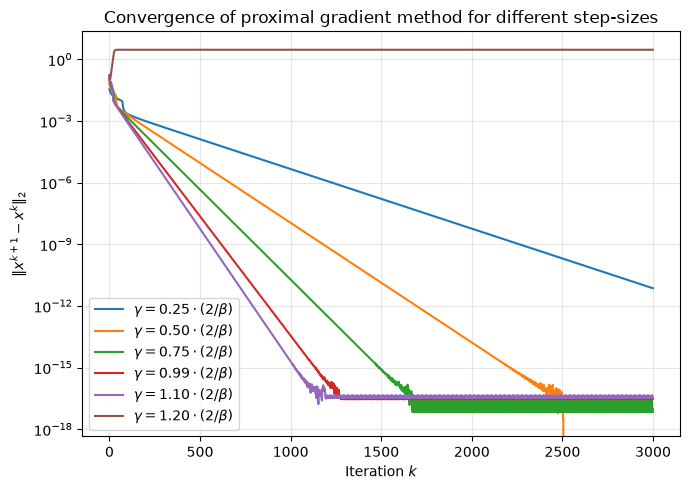

Recommended gamma = 0.99 * 2/beta = 0.029763


In [4]:

def prox_grad_primal(Q,q,gamma,k,x_inital): # Function to run the proximal gradient method
    x=x_inital # Init x.vector-just zeros
    residual =[] # list of res used in the plot
    for i in range (k):
        x_new = prox_box(x-gamma*grad_quad(x,Q,q),a,b,gamma) #  prox gradient step
        residual.append(np.linalg.norm(x_new-x)) # default of .linalg.norm is P=2 norm
        x=x_new # Update
    return x, residual

x_inital=np.zeros(len(q))
beta = np.linalg.eigvalsh(Q).max() #given from task 5
gamma_max = 2.0/beta # given in the instructions (max step size to get convergence)
gamma_frac = [0.25,0.5,0.75,0.99,1.1,1.2] #track the convergence rate
k =3000
plt.figure(figsize=(7,5))

for frac in gamma_frac: # try diffrent values for gamma
    gamma = frac*gamma_max
    _, residuals = prox_grad_primal(Q,q,gamma,k,x_inital)
    plt.semilogy(residuals, label=fr"$\gamma={frac:.2f}\cdot(2/\beta)$") # plots the log-linear plot

plt.xlabel("Iteration $k$")
plt.ylabel(r"$\|x^{k+1}-x^k\|_2$")
plt.title("Convergence of proximal gradient method for different step-sizes")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()
gamma_best = 0.99*gamma_max
print(f"Recommended gamma = 0.99 * 2/beta = {gamma_best:.6f}")

As one can see in the plot above the number of iterations decreases as the step-size $\gamma \rightarrow \frac{2}{ \beta}$. Hence, $0<\gamma < \frac{2}{\beta}$, otherwise the proximal gradient method do not converge, as can be seen in the plot above. According to the instructions, the algorithm has converged when the residual is less than $10^{-15}$ which is the case for some of the values for $\gamma$ in the plot above. If we increase the number of iterations, even smaller values for gamma such that $ 0<\gamma< \frac{2}{\beta}$, the residual will eventually converge towards zero. The best choice of $\gamma$ is therefore $0.99*\frac{2}{\beta}=0.0297$



__b)__ Does the upper bound $\gamma < \frac{2}{\beta}$ seem reasonable?

__Solution:__

From the plot above, this restriction of $\gamma$ is reasonable. For $1.1*\frac{2}{\beta}$ one can see that the residual is in the region for convergence but is still oscillating, hence not converged. For $1.2*\frac{2}{\beta}$ we are not even close to the region for convergence. Finally, for $0.99*\frac{2}{\beta}$ we reach convergence in the smallest number of iterations.



Test different initial points for the algorithm:

__c)__ Does this affect the point the algorithm converges to?

__Solution:__

As one can see in the print below, the initial points do not affect the points the algorithm converge to ($x^*$). Firstly, one can conclude that the model converge to a residual less than $10^{-15}$, as can be seen in the plot below. By then looking at norm of the final $x^*$ values for different initial points, one can easily conclude if the final points are the same or not. Using the print below, one can conclude that the difference between the final points, for the different initial points, is zero, in the meaning of machine precision. Hence, initial points do not affect the point the algorithm converges to.

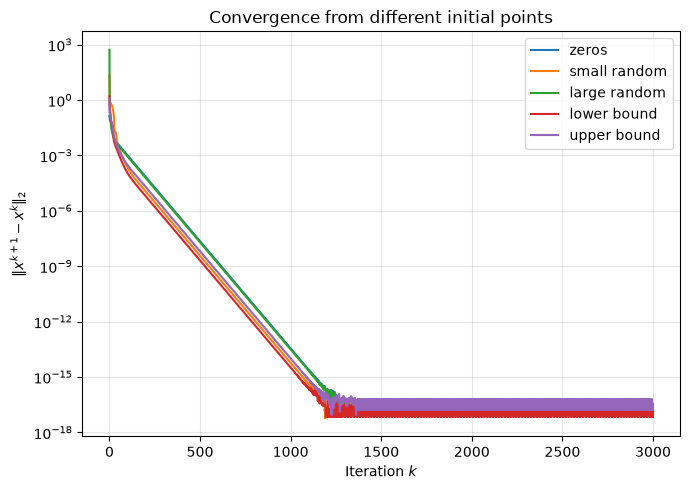

||x*_zeros - x*_zeros|| = 0.00e+00
||x*_small random - x*_zeros|| = 2.30e-15
||x*_large random - x*_zeros|| = 2.61e-15
||x*_lower bound - x*_zeros|| = 1.28e-16
||x*_upper bound - x*_zeros|| = 6.57e-16


In [5]:
rng = np.random.RandomState(0) # get the same random seed every time
initial_points = {
    "zeros": np.zeros(len(q)),
    "small random" : rng.randn(len(q))*5, # randn gives random nbr of N(0,1) centerd around zero
    "large random": rng.randn(len(q))*100, # larger random intital vector
    "lower bound": a.copy(), #start at the bound of our set
    "upper bound" : b.copy(),
}

results = {} # dict of results
plt.figure(figsize=(7,5))
for name, x0 in initial_points.items():# get both values and keys
    x_star, residuals = prox_grad_primal(Q,q,gamma_best,k,x0) # Use the function above, use the optimal gamma
    results[name] = x_star
    plt.semilogy(residuals, label=name) # Prints the conv. plot

plt.xlabel("Iteration $k$")
plt.ylabel(r"$\|x^{k+1}-x^k\|_2$")
plt.title("Convergence from different initial points")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

ref_name= "zeros" # We want to compare to the inital vector of zeros, can be any of the five
ref = results[ref_name]
for name, xstar in results.items(): # takes the keys (inital vector) and the values of the final point (x_star)
    diff = np.linalg.norm(xstar - ref) # compute the norm of this points
    print(f"||x*_{name} - x*_{ref_name}|| = {diff:.2e}")



__d)__ Carefully motivate theoretically why/why not it affects the final point. _Hint:_ Look at the objective function in $(2)$.

__Solution:__

The objective function is strongly convex and closed, and for every strongly convex closed function a unique minimizing point do exist. The proximal gradient method will converge to this point for $\gamma < \frac{2}{\beta}$. Therefore, regardless of the initial point, the method will converge to the unique minimizing point. Since $\nabla^2 f(x) \succ 0$, the smallest eigenvalue $\lambda_{min}(Q) > 0$, hence $\nabla^2 f(x) \succ \lambda_{min}(Q)I$ and the hessian has a quadratic lower bound, and the objective function is strongly convex. Since the indicator function is convex (see task 1) the objective function $f(x)+\iota_S$ is strongly convex because adding a convex function to a strongly convex function preserves strong convexity. Since, $f(x)$ is continuous on $R$ and $\iota_S$ is closed since $S$ is closed. Hence, the sum $f(x)+\iota_S$ is closed. The result of these observations motivate the answer above.


__e)__ Does your final point $x^{\text{final}}$ satisfy the constraint $x^{\text{final}} \in S$?

__Solution:__

This is tested below, and the result indicates that $x^{\text{final}} \in S$. The reason why is described in the following question.

In [6]:

for name, xstar in results.items(): # From the diffrent inintal vectors!
    in_box = np.all(xstar >= a) and np.all(xstar <= b) # xstar >= a builds an array of true and false, .all collapse everything to true or false, must be consensus for all to be true.
    print(f"{name:15s}: inside S = {in_box}")

zeros          : inside S = True
small random   : inside S = True
large random   : inside S = True
lower bound    : inside S = True
upper bound    : inside S = True



__f)__ What about the iterates, do they always satisfy the constraint, $x^k \in S$? Why/why not?

__Solution:__

Yes, for every iterate with $k>0$ $x^k \in S$. This holds since the proximal gradient step has a projection on $S$ for every step. In the code this is done in the function prox_box by the "clipping" np.minimum(np.maximum(x,a),b). However, the initial vector $x$ is not guaranteed to be in the box, but after one iteration every point is.


---
### Task 10:

Solve the dual problem.

__a)__ Similar to the previous task, find/verify the upper bound on the step-size and find a good step-size choice.

__Solution:__

_Fill in your solution here!_

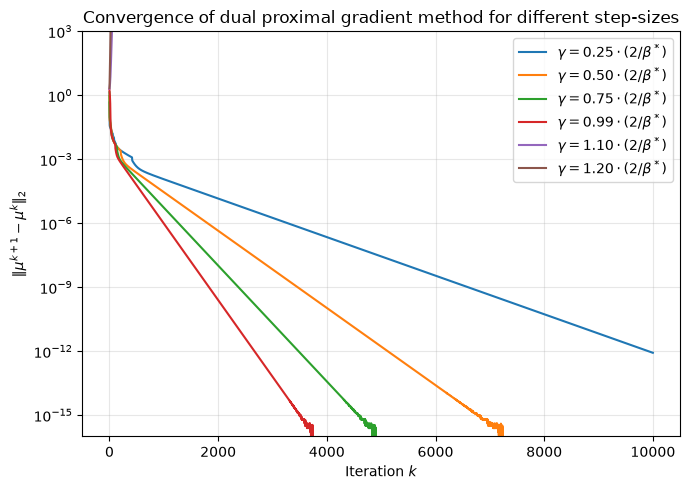

beta* = 15.7564, 2/beta* = 0.126933
Recommended gamma = 0.99 * 2/beta* = 0.125663


In [7]:
def prox_grad_dual(Q, q, a, b, gamma, k, mu_initial, divergence_tol=1e10):
    """
    Proximal gradient method on the dual problem
        minimize_mu  f*(mu) + iota_S*(-mu)
    using the update rule from Task 6.

    :param Q, q: data of the quadratic function f
    :param a, b: vectors defining the box S
    :param gamma: step-size
    :param k: number of iterations
    :param mu_initial: initial dual point
    :param divergence_tol: stop early if the residual exceeds this (method has diverged)
    :return: final mu, list of residuals ||mu^{k+1} - mu^k||_2, list of all iterates mu^k
    """
    mu = mu_initial.copy()
    residuals = []          # residual for each step
    iterates = [mu.copy()]  # all dual iterates that is used later

    for i in range(k):
        # gradient step on the smooth part f*
        v = mu - gamma * grad_quadconj(mu, Q, q)
        # prox step on g(mu) = i_S*(-mu): prox_{gamma g}(v) = -prox_{gamma i_S*}(-v)
        mu_new = -prox_boxconj(-v, a, b, gamma)
        residuals.append(np.linalg.norm(mu_new - mu))  # 2-norm
        mu = mu_new
        iterates.append(mu.copy())
        # top if the method diverges (happens for gamma > 2/beta*), before values overflow
        if residuals[-1] > divergence_tol:
            break
    return mu, residuals, iterates

mu_initial = np.zeros(len(q))
beta_star = 1.0 / np.linalg.eigvalsh(Q).min()   # beta* = 1/lambda_min(Q) from Task 4
gamma_max_dual = 2.0 / beta_star                # upper bound gamma < 2/beta*
gamma_frac = [0.25, 0.5, 0.75, 0.99, 1.1, 1.2]  # fractions of the upper bound to test
k = 10000                                        # same number of iterations as in Task 9

plt.figure(figsize=(7, 5))
for frac in gamma_frac:
    gamma = frac * gamma_max_dual
    _, residuals, _ = prox_grad_dual(Q, q, a, b, gamma, k, mu_initial)
    plt.semilogy(residuals, label=fr"$\gamma={frac:.2f}\cdot(2/\beta^*)$")  # log-linear plot

plt.ylim(1e-16, 1e3)  # cap the y-axis so diverging runs dont squash the convergent ones
plt.xlabel("Iteration $k$")
plt.ylabel(r"$\|\mu^{k+1}-\mu^k\|_2$")
plt.title("Convergence of dual proximal gradient method for different step-sizes")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

gamma_best_dual = 0.99 * gamma_max_dual
print(f"beta* = {beta_star:.4f}, 2/beta* = {gamma_max_dual:.6f}")
print(f"Recommended gamma = 0.99 * 2/beta* = {gamma_best_dual:.6f}")

As seen in the figure above, the dual method converges for all step-sizes below the upper bound $\gamma < \frac{2}{\beta^*}$, where $\beta^* = \frac{1}{\lambda_{\min}(Q)}$ from Task 4. For $\gamma = 1.1\cdot\frac{2}{\beta^*}$ and $\gamma = 1.2\cdot\frac{2}{\beta^*}$ the residual grows and the method diverges, which verifies the upper bound. The convergence is faster the closer $\gamma$ is to the bound, so a good choice is $\gamma = 0.99\cdot\frac{2}{\beta^*}$, which reaches a residual of about $10^{-13}$ within $k = 3000$ iterations.


Let $x^{\text{final}}$ be the final points from Task 9 and $\mu^{\text{final}}$ the final point for the dual problem. Let $\hat{x}^{\text{final}}$ final primal points extracted from the final dual point $\mu^{\text{final}}$ using the expression from Task 7:

__b)__ Are $x^{\text{final}}$ and $\hat{x}^{\text{final}}$ the same?

__Solution:__

_Fill in your solution here!_

In [8]:
import pandas as pd

k = 3000                             # same number of iterations as before
x_initial = np.zeros(len(q))
mu_initial = np.zeros(len(q))

# final primal point from Task 9
x_final, _ = prox_grad_primal(Q, q, gamma_best, k, x_initial) #vector size 20

# final dual point from 10a
mu_final, _, _ = prox_grad_dual(Q, q, a, b, gamma_best_dual, k, mu_initial) #vector size 20

# primal point extracted from the dual via task 7
x_hat_final = dual_to_primal(mu_final, Q, q, a, b) #vector size 20

# table comparing the two points component by component
comparison = pd.DataFrame({
    "a_i": a,
    "x_final": x_final,
    "x_hat_final": x_hat_final,
    "b_i": b,
    "|difference|": np.abs(x_final - x_hat_final),
})
comparison.index.name = "i"
display(comparison)

print(f"||x_final - x_hat_final||_2 = {np.linalg.norm(x_final - x_hat_final):.3e}")

,a_i,x_final,x_hat_final,b_i,|difference|
i,,,,,
0,-0.253741,-0.253741,-0.253741,0.937881,1.773026e-13
1,-0.384543,0.228424,0.228424,0.913528,8.795742e-14
2,-0.995297,0.257656,0.257656,0.865163,8.087975e-14
3,-0.208959,-0.208959,-0.208959,0.103488,3.611000e-13
4,-0.145742,0.149026,0.149026,0.767825,1.139089e-13
5,-0.390890,-0.026855,-0.026855,0.131777,1.186551e-13
6,-0.263868,-0.027765,-0.027765,0.405014,1.962944e-13
7,-0.432765,0.041322,0.041322,0.608992,1.071990e-13
8,-0.045274,0.397786,0.397786,0.439080,2.791101e-13


||x_final - x_hat_final||_2 = 9.000e-13


As seen in the table above, $\|x^{\text{final}} - \hat{x}^{\text{final}}\|_2 \approx 9\cdot 10^{-13}$. The table also shows the difference $|x^{\text{final}}_i - \hat{x}^{\text{final}}_i|$ for every component $i$, which is at most about $4\cdot 10^{-13}$. This is not exactly zero in the sense of machine precision ($\approx 10^{-15}$), but it is negligible, so the two solutions are effectively the same.


__c)__ Is $\hat{x}^{\text{final}}$ in the box $S$?

__Solution:__

In [9]:
# how far x_hat_final lies outside the box in each component (positive = violation)
viol_lower = a - x_hat_final   # > 0 means x_hat_i < a_i
viol_upper = x_hat_final - b   # > 0 means x_hat_i > b_i

# exact check vs. check with a small numerical tolerance
tol = 1e-10
print(f"Exactly in S:         {np.all(a <= x_hat_final) and np.all(x_hat_final <= b)}") #exact check
print(f"In S up to tol={tol}: {np.all(viol_lower <= tol) and np.all(viol_upper <= tol)}") #check with tol
print(f"Largest violation below a: {viol_lower.max():.3e}")
print(f"Largest violation above b: {viol_upper.max():.3e}")

# the primal final point from Task 9 for comparison
print(f"x_final exactly in S: {np.all(a <= x_final) and np.all(x_final <= b)}")

# table of the components that lie on the boundary of the box (active constraints)
active = np.isclose(x_hat_final, a) | np.isclose(x_hat_final, b)
boundary_table = pd.DataFrame({
    "a_i": a[active],
    "x_hat_final": x_hat_final[active],
    "b_i": b[active],
    "x_hat - a": -viol_lower[active],
    "b - x_hat": -viol_upper[active],
})
boundary_table.index = np.where(active)[0]
boundary_table.index.name = "i"
display(boundary_table)

Exactly in S:         False
In S up to tol=1e-10: True
Largest violation below a: 3.611e-13
Largest violation above b: 8.116e-14
x_final exactly in S: True


,a_i,x_hat_final,b_i,x_hat - a,b - x_hat
i,,,,,
0,-0.253741,-0.253741,0.937881,1.773026e-13,1.191622e+00
3,-0.208959,-0.208959,0.103488,-3.611000e-13,3.124470e-01
16,-0.119781,0.016314,0.016314,1.360944e-01,2.894351e-13
18,-0.211778,0.524830,0.524830,7.366081e-01,-8.115730e-14
19,-0.231118,0.286896,0.286896,5.180145e-01,6.694645e-14


The solution is in S to numerical precision. As seen in the output and table above, $\hat{x}^{\text{final}}$ violates the box constraint by at most about $10^{-13}$ and only in the components that lie on the boundary of $S$. In contrast, $x^{\text{final}}$ from Task 9 lies exactly in $S$.

The reason is how the two points are produced. The primal method ends every iteration with $\operatorname{prox}_{\gamma\iota_S}$ which is the projection onto $S$ which forces each component into $[a_i,b_i]$, so every iterate is exactly in $S$. The point $\hat{x}^{\text{final}} = Q^{-1}(\mu^{\text{final}} - q)$ is instead computed from the dual point, and nothing in this formula ensures that the result lies in $S$. Task 7 shows $\hat{x}\in S$ only at an exact dual solution $\mu^\star$. Since $\mu^{\text{final}}$ is only an approximation of $\mu^\star$, $\hat{x}^{\text{final}}$ can end up slightly outside $S$ in the components where the solution lies exactly on the boundary.


__d)__ Let $\mu^k$ be the iterates of the dual method, using the expression from Task 7, extract the primal iterates $\hat{x}^k$ from $\mu^k$. Does $\hat{x}^k$ always satisfy the constraint $\hat{x}^k \in S$?

__Solution:__

_Fill in your solution here!_

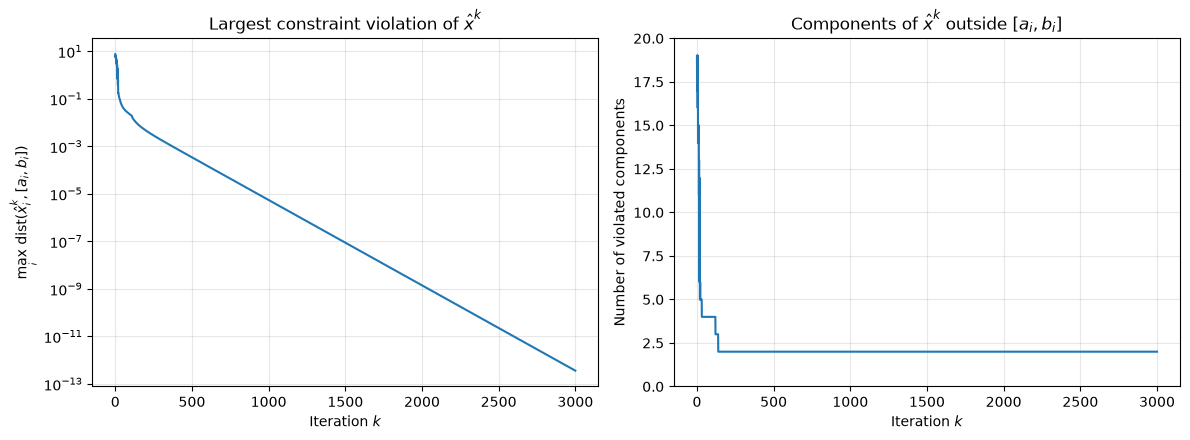

Iterates exactly in S: 0 of 3001


In [10]:
# rerun dual method, keep all iterates
_, _, mu_iterates = prox_grad_dual(Q, q, a, b, gamma_best_dual, k, mu_initial)

# primal iterates from task 7: x_hat = Q^{-1}(mu - q)
x_hat_iterates = np.array([dual_to_primal(mu, Q, q, a, b) for mu in mu_iterates])

# distance outside [a_i, b_i] per component, 0 if inside
violation = np.maximum(np.maximum(a - x_hat_iterates, x_hat_iterates - b), 0)
max_violation = violation.max(axis=1)       # largest violation per iteration
num_violated = (violation > 0).sum(axis=1)  # violated components per iteration

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# largest violation, log scale
ax1.semilogy(max_violation)
ax1.set_xlabel("Iteration $k$")
ax1.set_ylabel(r"$\max_i \, \mathrm{dist}(\hat{x}^k_i, [a_i, b_i])$")
ax1.set_title(r"Largest constraint violation of $\hat{x}^k$")
ax1.grid(True, which="both", alpha=0.3)

# number of violated components
ax2.plot(num_violated)
ax2.set_xlabel("Iteration $k$")
ax2.set_ylabel("Number of violated components")
ax2.set_title(r"Components of $\hat{x}^k$ outside $[a_i, b_i]$")
ax2.set_ylim(0, len(q))
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Iterates exactly in S: {np.sum(num_violated == 0)} of {len(num_violated)}")

No. The figure above shows the constraint violation of the extracted primal iterates $\hat{x}^k = Q^{-1}(\mu^k - q)$ over the iterations.

The left plot shows the largest distance from any component $\hat{x}^k_i$ to its interval $[a_i,b_i]$. In the first iterations it is about $7.6$, so $\hat{x}^k$ is far outside the box. We can see that the violations decrease as the iterations continue but one of the iterates lie exactly in $S$.

The right plot shows how many of the 20 components lie outside their interval. At the start almost all components violate the constraint. This number drops quickly and settles at 2 after a few hundred iterations. These remaining components are active constraints at the solution (see Task 10c), which $\hat{x}^k$ approaches from outside the box.

The reason is that $\hat{x}^k$ is obtained through the affine map $Q^{-1}(\mu^k - q)$, which does not enforce the box constraint. Task 7 only guarantees $\hat{x}\in S$ at an exact dual solution $\mu^\star$, so feasibility is only reached in the limit as $\mu^k\to\mu^\star$. This is in contrast to the primal method in Task 9, where every iterate ends with a projection onto $S$ and therefore always satisfies the constraint.


__e)__ How do the function values $f\left(\hat{x}^k\right)$ develop over the iterations?

__Solution:__

_Fill in your solution here!_

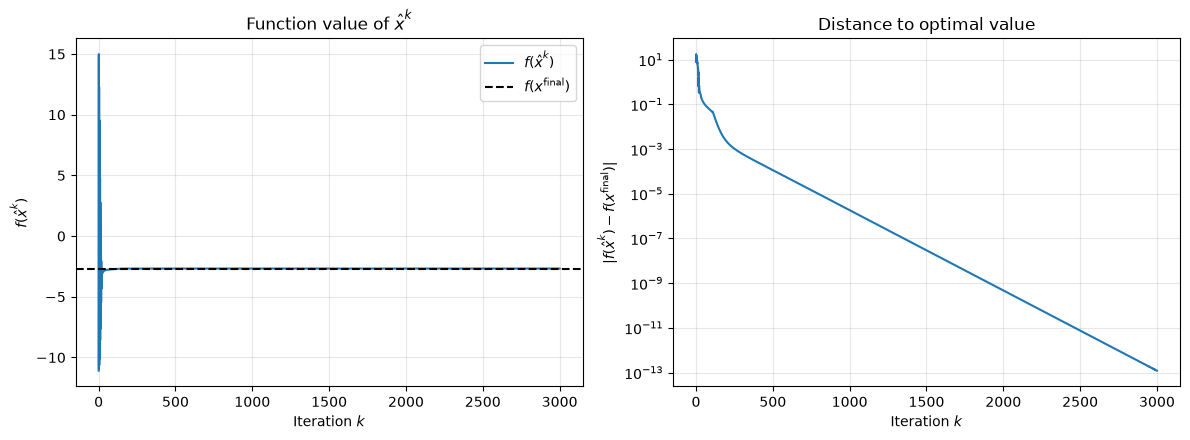

f(x_final) = -2.673542


In [11]:
# f at  extracted primal iterates and at primal solution from task 9
f_hat = np.array([quad(x, Q, q) for x in x_hat_iterates])
f_star = quad(x_final, Q, q)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# f(x_hat^k) compared to the optimal value
ax1.plot(f_hat, label=r"$f(\hat{x}^k)$")
ax1.axhline(f_star, color="k", linestyle="--", label=r"$f(x^{\mathrm{final}})$")
ax1.set_xlabel("Iteration $k$")
ax1.set_ylabel(r"$f(\hat{x}^k)$")
ax1.set_title(r"Function value of $\hat{x}^k$")
ax1.legend()
ax1.grid(True, alpha=0.3)

# distance to the optimal value, log scale
ax2.semilogy(np.abs(f_hat - f_star))
ax2.set_xlabel("Iteration $k$")
ax2.set_ylabel(r"$|f(\hat{x}^k) - f(x^{\mathrm{final}})|$")
ax2.set_title("Distance to optimal value")
ax2.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

print(f"f(x_final) = {f_star:.6f}")


__f)__ What about $f\left(\hat{x}^k\right)+\iota_{S}\left(\hat{x}^k\right)$?

__Solution:__

_Fill in your solution here!_



$f(\hat{x}^k) + \iota_S(\hat{x}^k) = \infty$ for all iterations since none of the iterates $f(\hat{x}^k)$ lie in $S$. This makes the indicator function take the value $\infty$ for all $f(\hat{x}^k)$.